# 19 — LSTM (Long Short-Term Memory)

**Architecture:** Embedding → LSTM(128) → Dense(64, relu) → Dropout(0.3) → Dense(1, sigmoid)  
**Features:** Token sequences (max 200 tokens, vocab 30K)  
LSTMs use gating mechanisms (input/forget/output) to preserve long-range dependencies across sequences — well-suited to variable-length news text.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, plot_confusion_matrix, plot_roc_curve, plot_pr_curve)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve,
                              precision_recall_curve, average_precision_score)
BASE_DIR, FIGURES_DIR = setup_paths()

try:
    import tensorflow as tf
    print(f'TensorFlow {tf.__version__}  |  GPU: {tf.config.list_physical_devices("GPU")}')
except ImportError:
    raise ImportError('TensorFlow required. Run: pip install tensorflow')

TensorFlow 2.21.0  |  GPU: []


In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


## Tokenisation

In [3]:
MAX_WORDS = 30000
MAX_LEN   = 200
MAX_SAMPLES = 80000

if len(X_train) > MAX_SAMPLES:
    np.random.seed(42)
    idx = np.random.choice(len(X_train), MAX_SAMPLES, replace=False)
    X_tr_raw, y_tr = X_train[idx], y_train[idx]
else:
    X_tr_raw, y_tr = X_train, y_train
print(f'Training on {len(X_tr_raw):,} samples')

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_tr_raw)
X_tr = pad_sequences(tokenizer.texts_to_sequences(X_tr_raw), maxlen=MAX_LEN, padding='post', truncating='post')
X_te = pad_sequences(tokenizer.texts_to_sequences(X_test),   maxlen=MAX_LEN, padding='post', truncating='post')
vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)
print(f'Vocabulary: {vocab_size:,}  |  Sequence length: {MAX_LEN}')

Training on 80,000 samples
Vocabulary: 30,000  |  Sequence length: 200


## Model Architecture

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

EMBEDDING_DIM = 128
MODEL_NAME = 'LSTM'

model = Sequential([
    Embedding(vocab_size, EMBEDDING_DIM, input_length=MAX_LEN),
    LSTM(128, dropout=0.2, recurrent_dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
], name='LSTM')
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Training

In [5]:
early_stop = EarlyStopping(monitor='val_loss', patience=3,
                           restore_best_weights=True, verbose=1)
t0 = time.time()
history = model.fit(
    X_tr, y_tr,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)
train_time = time.time() - t0
print(f'\nTraining completed in {train_time:.1f}s')

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 340s 300ms/step - accuracy: 0.6921 - loss: 0.5988 - val_accuracy: 0.7048 - val_loss: 0.5976
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 303s 270ms/step - accuracy: 0.7278 - loss: 0.5433 - val_accuracy: 0.7284 - val_loss: 0.5627
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 387s 344ms/step - accuracy: 0.7430 - loss: 0.5027 - val_accuracy: 0.7489 - val_loss: 0.4483
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 421s 375ms/step - accuracy: 0.7913 - loss: 0.3848 - val_accuracy: 0.8010 - val_loss: 0.3830
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 395s 351ms/step - accuracy: 0.8413 - loss: 0.3078 - val_accuracy: 0.8181 - val_loss: 0.3743
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 310s 276ms/step - accuracy: 0.8802 - loss: 0.2456 - val_accuracy: 0.8280 - val_loss: 0.3878
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 378s 336ms/step - accuracy: 0.9123 - loss: 0.1928 - val_accuracy: 0.8276 - val_loss: 0.4432
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 350s 311ms/step - ac

## Training Convergence: Loss & Accuracy per Epoch

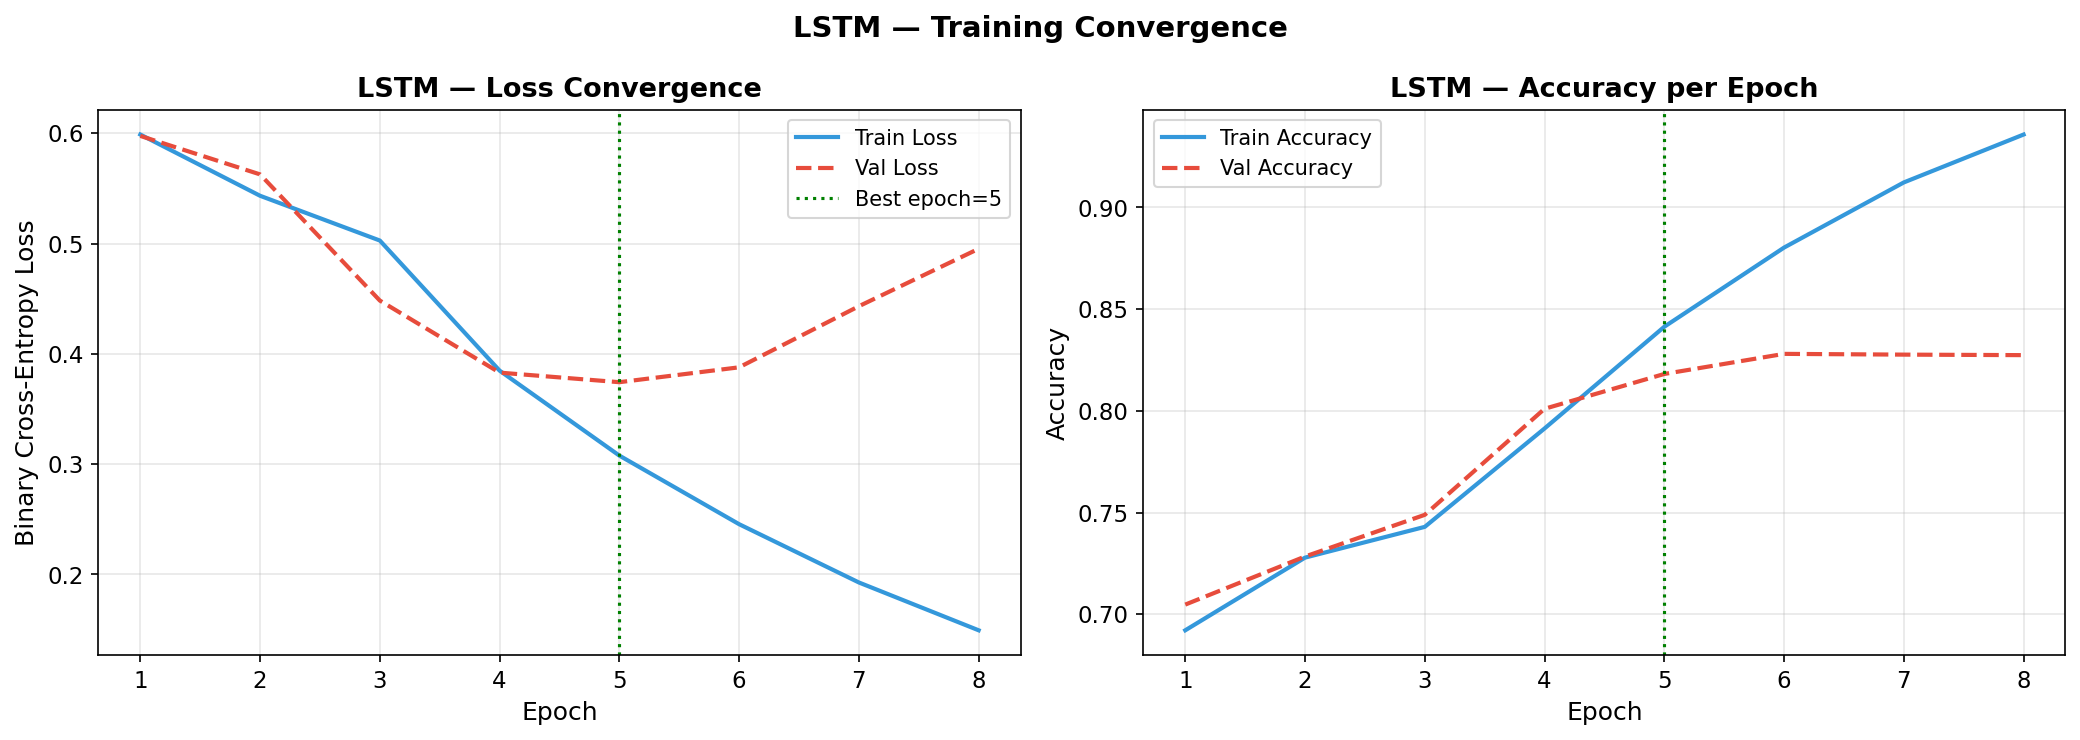

In [6]:
hist = history.history
epochs_run = range(1, len(hist['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(epochs_run, hist['loss'],     color='#3498db', lw=2, label='Train Loss')
axes[0].plot(epochs_run, hist['val_loss'], color='#e74c3c', lw=2, label='Val Loss', linestyle='--')
best_ep = np.argmin(hist['val_loss']) + 1
axes[0].axvline(best_ep, color='green', linestyle=':', lw=1.5, label=f'Best epoch={best_ep}')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].set_title('LSTM — Loss Convergence')
axes[0].legend(fontsize=10); axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(epochs_run, hist['accuracy'],     color='#3498db', lw=2, label='Train Accuracy')
axes[1].plot(epochs_run, hist['val_accuracy'], color='#e74c3c', lw=2, label='Val Accuracy', linestyle='--')
axes[1].axvline(best_ep, color='green', linestyle=':', lw=1.5)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('LSTM — Accuracy per Epoch')
axes[1].legend(fontsize=10); axes[1].grid(alpha=0.3)

plt.suptitle('LSTM — Training Convergence', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'lstm_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

## Evaluation Metrics

In [7]:
y_prob = model.predict(X_te, verbose=0).flatten()
y_pred = (y_prob >= 0.5).astype(int)

metrics = {
    'Accuracy':      accuracy_score(y_test, y_pred),
    'Precision':     precision_score(y_test, y_pred, average='weighted', zero_division=0),
    'Recall':        recall_score(y_test, y_pred, average='weighted', zero_division=0),
    'F1 Score':      f1_score(y_test, y_pred, average='weighted', zero_division=0),
    'AUC-ROC':       roc_auc_score(y_test, y_prob),
    'Train Time (s)': round(train_time, 2),
}
for k, v in metrics.items():
    print(f'  {k:<20}: {v:.4f}' if k != 'Train Time (s)' else f'  {k:<20}: {v:.2f}s')
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['Fake', 'Real']))

  Accuracy            : 0.8203
  Precision           : 0.8195
  Recall              : 0.8203
  F1 Score            : 0.8196
  AUC-ROC             : 0.9111
  Train Time (s)      : 2884.60s

Classification Report:
              precision    recall  f1-score   support

        Fake       0.79      0.76      0.77      8532
        Real       0.84      0.86      0.85     12373

    accuracy                           0.82     20905
   macro avg       0.82      0.81      0.81     20905
weighted avg       0.82      0.82      0.82     20905



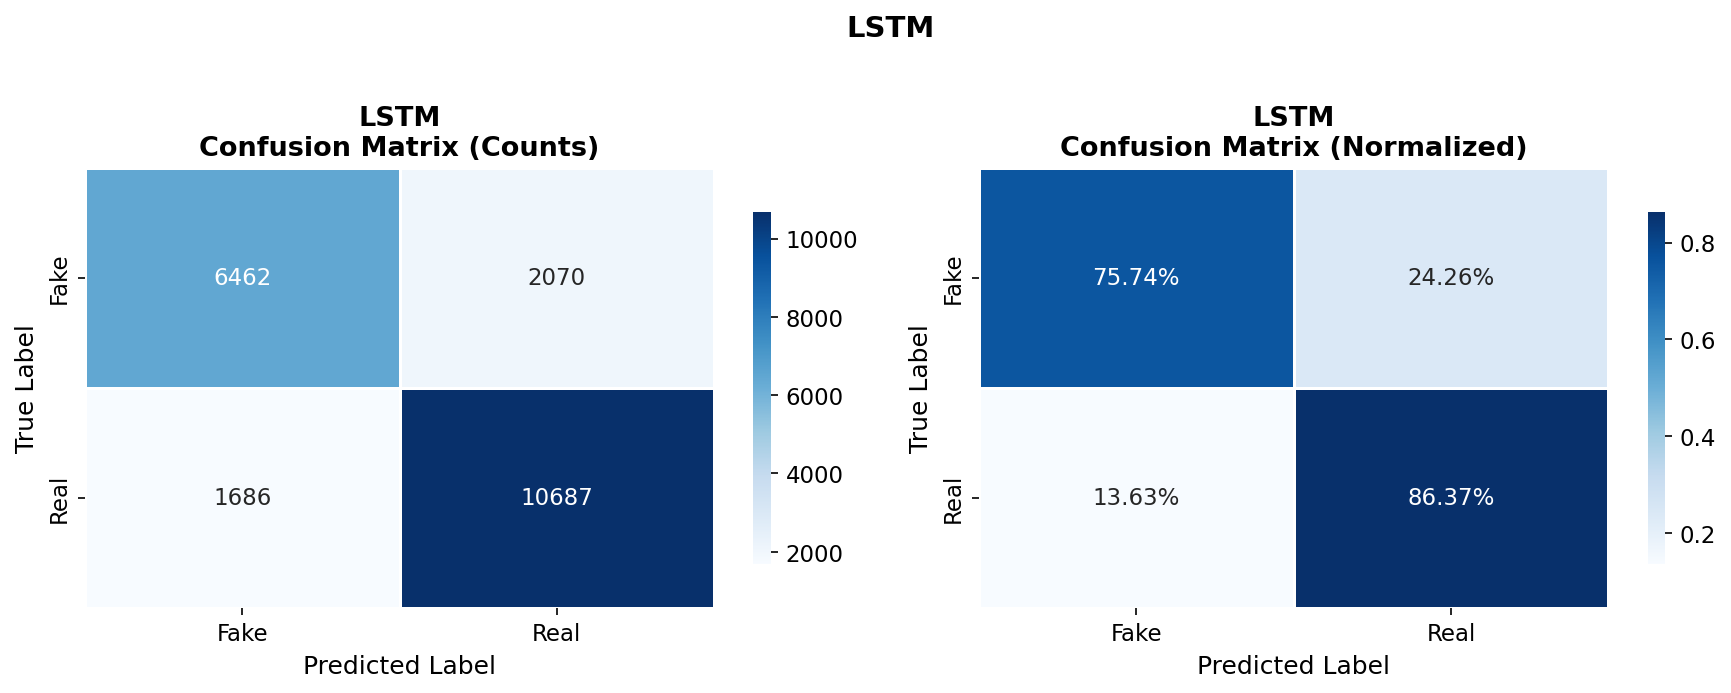

In [8]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

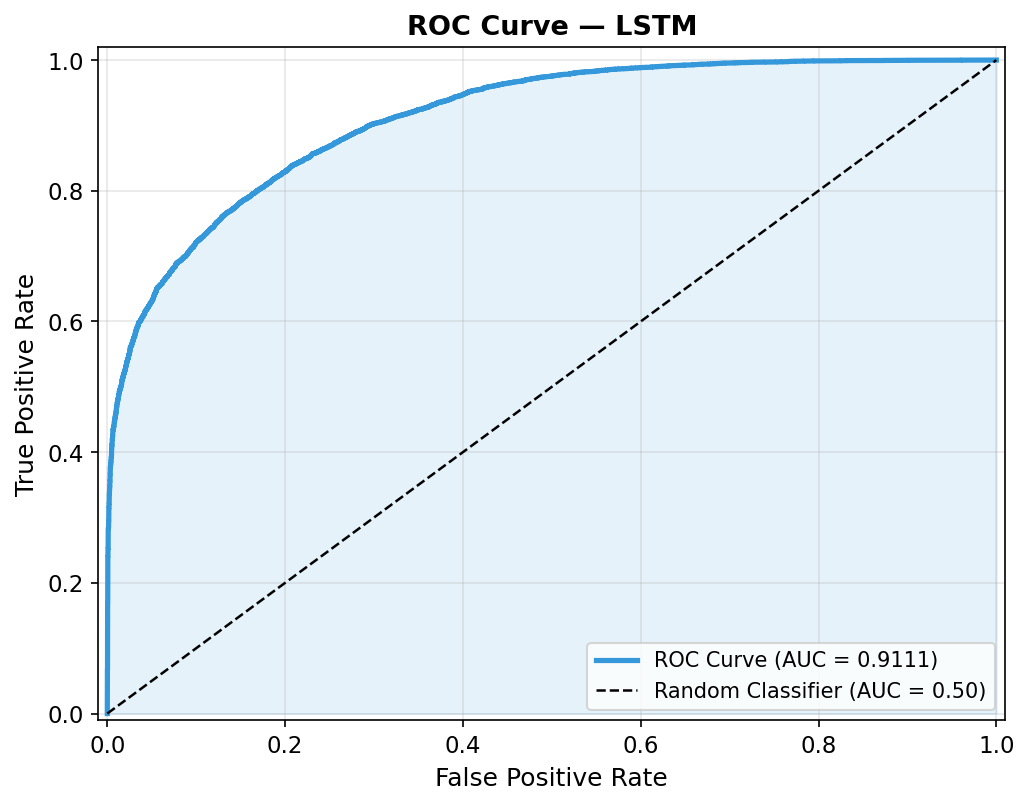

In [9]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

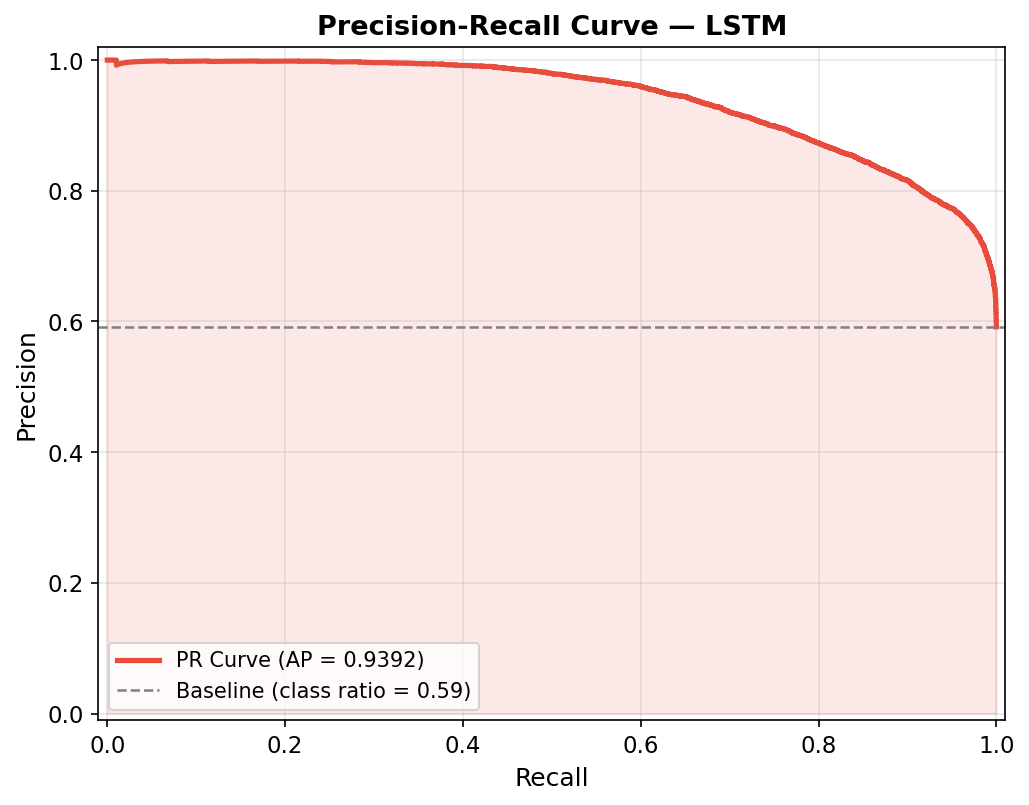

In [10]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Prediction Score Distribution

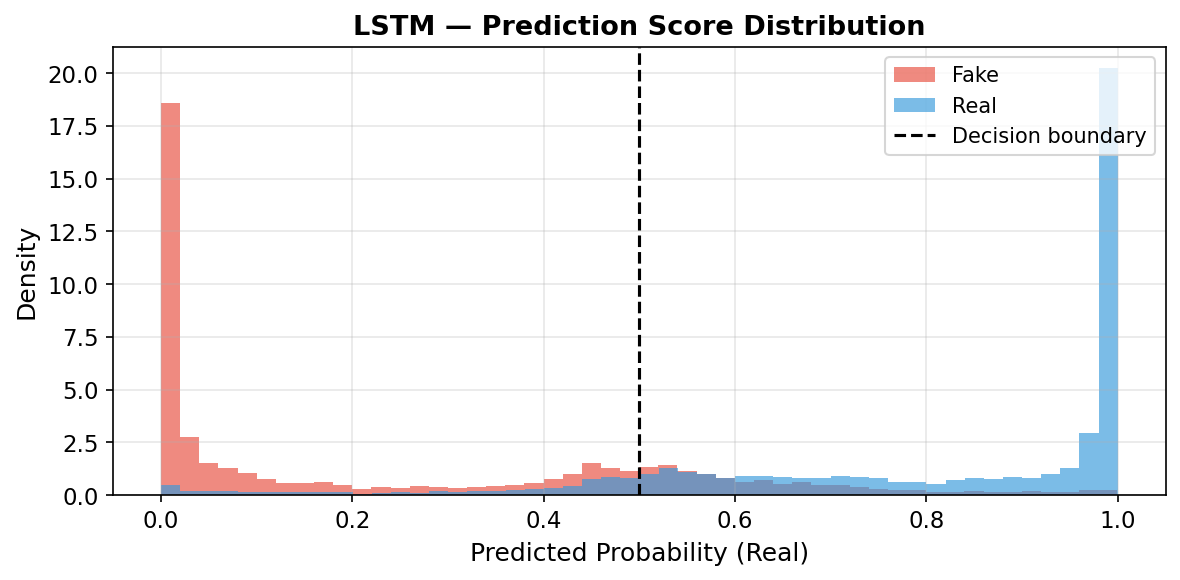

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_prob[y_test == 0], bins=50, alpha=0.65, color='#e74c3c', label='Fake', density=True)
ax.hist(y_prob[y_test == 1], bins=50, alpha=0.65, color='#3498db', label='Real', density=True)
ax.axvline(0.5, color='black', linestyle='--', lw=1.5, label='Decision boundary')
ax.set_xlabel('Predicted Probability (Real)')
ax.set_ylabel('Density')
ax.set_title('LSTM — Prediction Score Distribution')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'lstm_score_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()